# LG TV conversion: initial analysis

**Working question — proposed refinement:** How does LG compare with Samsung in moving
from a TV view to a cart, and from an eligible cart to a purchase, after accounting for initial price and month?

One observation is a **user × session × product** with a view. Events must occur strictly later
to count as a transition. Rates describe product considerations, not independent customers.
This is a historical retailer proxy (October–November 2019), not current LG performance.

## Cell guide

The numbers below match the `# 01`–`# 14` labels in the code. Run the core cells in order.
Cells 10–11 are optional sensitivity checks; the models do not depend on them.

| Block | Purpose | Importance for this study |
|---|---|---|
| 01 | Load the behavioural CSV using the local relative path. | Essential setup |
| 02 | Check missing values, prices, duplicates and product labels. | Essential data quality |
| 03 | Select the agreed period, TV category and two brands. | Essential scope |
| 04 | Identify the first view, first later cart and last purchase. | Essential measurement |
| 05 | Create the consideration table and two stage outcomes. | Essential measurement |
| 06 | Calculate stage rates, counts and LG–Samsung gaps. | Central descriptive evidence |
| 07 | Compare the same rates by month. | Important context |
| 08 | Compare initial-price distributions. No price filter. | Important comparability check |
| 09 | Check top-product concentration and repeated users. | Important limits/inference check |
| 10 | Recalculate stage rates without each brand's top product. | Optional sensitivity |
| 11 | Recalculate stage rates for users who considered both brands. | Optional sensitivity; selected users |
| 12 | Prepare the two model samples and controls. | Essential for modelling |
| 13 | Fit a view-to-cart Logit and compare predicted probabilities. | Preliminary main model |
| 14 | Fit a cart-to-purchase Logit and compare predicted probabilities. | Preliminary conditional model |

All displayed results are calculated from the loaded CSV. There are no embedded reference rates.
The code uses pandas, NumPy, matplotlib and statsmodels in the selected notebook environment.


In [2]:
# 01. Load the events from the private data folder.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('..') / 'data' / '01_LG_Electronics_Appliances'
df_behavior = pd.read_csv(DATA_DIR / 'electronics_market_behavior.csv')
events = df_behavior.copy()
events['event_time'] = pd.to_datetime(events['event_time'], utc=True)
key = ['user_id', 'session_id', 'product_id']
print('Behavioural events:', len(events))


Behavioural events: 649605


In [3]:
# 02. Check the input before building the sample. Exact duplicates stay in the raw data.
display(events.isna().sum().rename('missing_values').to_frame())
print('Date range:', events['event_time'].min(), 'to', events['event_time'].max())
print('Duplicate events:', events.duplicated().sum())
print('Session IDs shared across users:', (events.groupby('session_id')['user_id'].nunique() > 1).sum())
assert events.notna().all().all()
assert np.isfinite(events['price']).all() and (events['price'] > 0).all()
assert events['event_type'].isin(['view', 'cart', 'purchase']).all()
assert (events.groupby('product_id')[['brand', 'product_category']].nunique() == 1).all().all()


,missing_values
event_time,0
event_type,0
user_id,0
session_id,0
product_id,0
product_category,0
brand,0
price,0


Date range: 2019-10-01 00:06:07+00:00 to 2019-11-30 23:56:30+00:00
Duplicate events: 1247
Session IDs shared across users: 4


In [4]:
# 03. Select the period, category and brands, showing the number of events retained.
period = events[(events['event_time'] >= '2019-10-01') & (events['event_time'] < '2019-12-01')]
televisions = period[period['product_category'] == 'tv']
tv = televisions[televisions['brand'].isin(['lg', 'samsung'])].copy()
display(pd.Series({'Raw events': len(events), 'Events in period': len(period),
                   'TV events': len(televisions), 'LG/Samsung TV events': len(tv)}, name='event_rows'))


Raw events              649605
Events in period        649605
TV events               212303
LG/Samsung TV events    135411
Name: event_rows, dtype: int64

In [5]:
# 04. Find the start of each consideration and its later journey events.
views = tv[tv['event_type'] == 'view']
first_views = views.sort_values('event_time', kind='stable').drop_duplicates(key)
first_views = first_views[key + ['brand', 'price', 'event_time']].rename(
    columns={'price': 'initial_price', 'event_time': 'first_view'})
purchases = tv[tv['event_type'] == 'purchase']
last_purchases = purchases.groupby(key)['event_time'].max().reset_index(name='last_purchase')
carts = tv[tv['event_type'] == 'cart'].merge(first_views[key + ['first_view']], on=key)
carts = carts[carts['event_time'] > carts['first_view']]
first_carts = carts.groupby(key)['event_time'].min().reset_index(name='first_cart')
# The last purchase tells us whether ANY purchase happened after the first view/cart.


In [6]:
# 05. Build one row per viewed user-session-product and define the two stage outcomes.
baseline_full = first_views.merge(first_carts, on=key, how='left').merge(last_purchases, on=key, how='left')
baseline_full['has_cart'] = baseline_full['first_cart'].notna().astype(int)
baseline_full['purchase_after_cart'] = (baseline_full['last_purchase'] > baseline_full['first_cart']).astype(int)
baseline_full['Y'] = (baseline_full['last_purchase'] > baseline_full['first_view']).astype(int)
baseline_full['month'] = baseline_full['first_view'].dt.strftime('%Y-%m')
assert not baseline_full.duplicated(key).any()
assert (baseline_full['purchase_after_cart'] <= baseline_full['has_cart']).all()
print('Considerations:', len(baseline_full), '| Users:', baseline_full['user_id'].nunique())
print('Purchases without a qualifying cart path:', (baseline_full['Y'] - baseline_full['purchase_after_cart']).sum())
print('First views on the final day:', (baseline_full['first_view'] >= '2019-11-30').sum())
# Zero means no qualifying transition observed in this unit, not no purchase anywhere.


Considerations: 74712 | Users: 35871
Purchases without a qualifying cart path: 446
First views on the final day: 1114


In [7]:
# 06. Calculate the two stage rates and overall conversion from their own denominators.
kpis = baseline_full.groupby('brand').agg(
    considerations=('Y', 'size'), carts=('has_cart', 'sum'),
    purchases_after_cart=('purchase_after_cart', 'sum'), purchases=('Y', 'sum'))
kpis['view_to_cart_pct'] = 100 * kpis['carts'] / kpis['considerations']
kpis['cart_to_purchase_pct'] = 100 * kpis['purchases_after_cart'] / kpis['carts'].replace(0, np.nan)
kpis['view_to_purchase_pct'] = 100 * kpis['purchases'] / kpis['considerations']
display(kpis.round(2))
rate_columns = ['view_to_cart_pct', 'cart_to_purchase_pct', 'view_to_purchase_pct']
display((kpis.loc['lg', rate_columns] - kpis.loc['samsung', rate_columns]).rename('LG_minus_Samsung_pp'))
# Cart users are a selected subset. The two stage rates do not identify causes of lost sales.


,considerations,carts,purchases_after_cart,purchases,view_to_cart_pct,cart_to_purchase_pct,view_to_purchase_pct
brand,,,,,,,
lg,22213,1073,374,505,4.83,34.86,2.27
samsung,52499,3311,1330,1645,6.31,40.17,3.13


view_to_cart_pct       -1.476282
cart_to_purchase_pct   -5.313588
view_to_purchase_pct   -0.859950
Name: LG_minus_Samsung_pp, dtype: float64

In [8]:
# 07. Check whether the stage differences also appear within each month.
monthly = baseline_full.groupby(['brand', 'month']).agg(
    considerations=('Y', 'size'), carts=('has_cart', 'sum'), purchases_after_cart=('purchase_after_cart', 'sum'))
monthly['view_to_cart_pct'] = 100 * monthly['carts'] / monthly['considerations']
monthly['cart_to_purchase_pct'] = 100 * monthly['purchases_after_cart'] / monthly['carts'].replace(0, np.nan)
display(monthly.round(2))
# Month is defined by the first view here; stage-two modelling uses the month of cart entry.


considerations  carts  ...  view_to_cart_pct  cart_to_purchase_pct
brand   month                           ...                                        
lg      2019-10            6770    210  ...              3.10                 44.76
        2019-11           15443    863  ...              5.59                 32.44
samsung 2019-10           18494   1053  ...              5.69                 46.25
        2019-11           34005   2258  ...              6.64                 37.33

[4 rows x 5 columns]

,0.05,0.25,0.50,0.75,0.95
brand,,,,,
lg,295.35,390.86,460.84,666.27,1413.63
samsung,288.04,381.74,493.96,635.25,1415.71


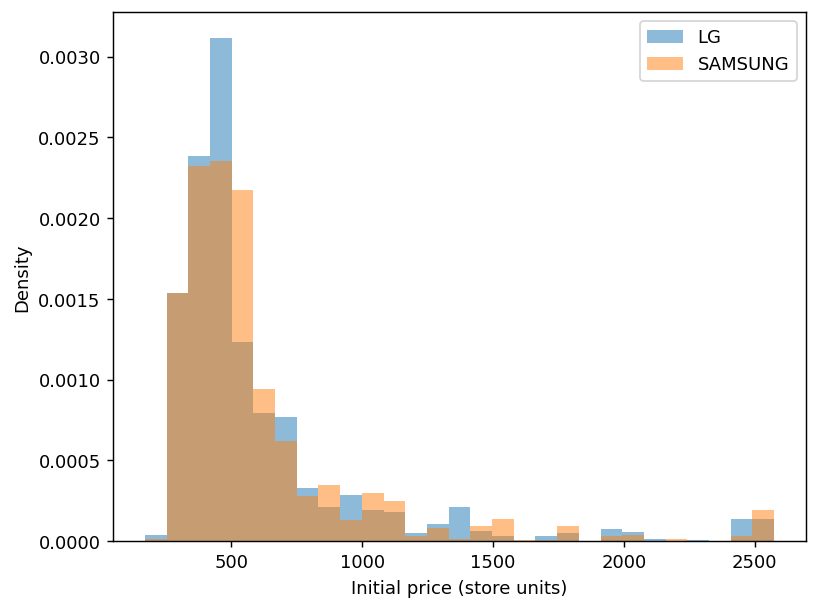

In [9]:
# 08. Inspect price overlap. We have not selected a price restriction.
display(baseline_full.groupby('brand')['initial_price'].quantile([.05, .25, .5, .75, .95]).unstack().round(2))
bins = np.linspace(baseline_full['initial_price'].min(), baseline_full['initial_price'].max(), 30)
for brand in ['lg', 'samsung']:
    prices = baseline_full.loc[baseline_full['brand'] == brand, 'initial_price']
    plt.hist(prices, bins=bins, density=True, alpha=.5, label=brand.upper())
plt.xlabel('Initial price (store units)')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()
# Price overlap does not establish equivalent TV specifications or availability.


In [10]:
# 09. Check whether a few products or repeated users dominate the comparison.
products = baseline_full.groupby(['brand', 'product_id']).size().reset_index(name='considerations')
ranked_products = products.sort_values(['brand', 'considerations', 'product_id'], ascending=[True, False, True])
top5_counts = ranked_products.groupby('brand').head(5).groupby('brand')['considerations'].sum()
display((100 * top5_counts / kpis['considerations']).rename('top5_share_of_brand_rows_pct'))
user_counts = baseline_full.groupby('user_id').size()
print('Users with repeated rows:', (user_counts > 1).sum())
print('Share of rows from repeated users (%):', 100 * user_counts[user_counts > 1].sum() / len(baseline_full))
# Every reported value is calculated, including the product-concentration percentages.


brand
lg         42.308558
samsung    52.381950
Name: top5_share_of_brand_rows_pct, dtype: float64

Users with repeated rows: 15561
Share of rows from repeated users (%): 72.81561194988757


In [11]:
# 10. Optional: test the stage rates without the most-considered product of each brand.
removed_products = ranked_products.groupby('brand').head(1)
display(removed_products)
exclude_top_viewed = baseline_full[~baseline_full['product_id'].isin(removed_products['product_id'])].copy()
sensitivity = exclude_top_viewed.groupby('brand').agg(
    considerations=('Y', 'size'), carts=('has_cart', 'sum'), purchases_after_cart=('purchase_after_cart', 'sum'))
sensitivity['view_to_cart_pct'] = 100 * sensitivity['carts'] / sensitivity['considerations']
sensitivity['cart_to_purchase_pct'] = 100 * sensitivity['purchases_after_cart'] / sensitivity['carts'].replace(0, np.nan)
display(sensitivity.round(2))
# This changes the assortment. The full sample remains the main comparison.


,brand,product_id,considerations
92,lg,P000640,2723
136,samsung,P000507,9106


,considerations,carts,purchases_after_cart,view_to_cart_pct,cart_to_purchase_pct
brand,,,,,
lg,19490,905,315,4.64,34.81
samsung,43393,2436,946,5.61,38.83


In [12]:
# 11. Optional: compare the same two stages among users who considered both brands.
brand_counts = baseline_full.groupby('user_id')['brand'].nunique()
dual_brand_ids = brand_counts[brand_counts == 2].index
dual_brand_users = baseline_full[baseline_full['user_id'].isin(dual_brand_ids)].copy()
dual_kpis = dual_brand_users.groupby('brand').agg(
    considerations=('Y', 'size'), carts=('has_cart', 'sum'), purchases_after_cart=('purchase_after_cart', 'sum'))
dual_kpis['view_to_cart_pct'] = 100 * dual_kpis['carts'] / dual_kpis['considerations']
dual_kpis['cart_to_purchase_pct'] = 100 * dual_kpis['purchases_after_cart'] / dual_kpis['carts'].replace(0, np.nan)
print('Users considering both brands:', len(dual_brand_ids))
display(dual_kpis.round(2))
# These are selected users, not a matched or randomised comparison. No fixed-effects model is fitted.


,considerations,carts,purchases_after_cart,view_to_cart_pct,cart_to_purchase_pct
brand,,,,,
lg,12194,440,137,3.61,31.14
samsung,15833,578,175,3.65,30.28


Users considering both brands: 6364


In [13]:
# 12. Prepare the samples for two preliminary binary Logit models.
import statsmodels.formula.api as smf

view_sample = baseline_full.copy()
view_sample['LG'] = (view_sample['brand'] == 'lg').astype(int)
view_sample['log_price'] = np.log(view_sample['initial_price'])
view_sample['entry_month'] = view_sample['first_view'].dt.strftime('%Y-%m')
cart_sample = view_sample[view_sample['has_cart'] == 1].copy()
cart_sample['entry_month'] = cart_sample['first_cart'].dt.strftime('%Y-%m')
display(pd.DataFrame({'stage': ['View to cart', 'Cart to purchase'],
                      'observations': [len(view_sample), len(cart_sample)],
                      'positive_outcomes': [view_sample['has_cart'].sum(), cart_sample['purchase_after_cart'].sum()]}))
# Both models use price known at the first view and month of entry into their own stage.
# Grouped standard errors account for repeated users; product dependence remains a limitation.


,stage,observations,positive_outcomes
0,View to cart,74712,4384
1,Cart to purchase,4384,1704


In [14]:
# 13. Model the probability of an eligible cart after a view; Samsung is the reference.
view_cart_model = smf.logit('has_cart ~ LG + log_price + C(entry_month)', data=view_sample).fit(
    disp=False, cov_type='cluster', cov_kwds={'groups': view_sample['user_id']})
print('View-to-cart model converged:', view_cart_model.mle_retvals['converged'])
display(view_cart_model.summary2().tables[1])
# Compare average probabilities using the same observed price/month distribution for both brands.
lg_profiles = view_sample.assign(LG=1)
samsung_profiles = view_sample.assign(LG=0)
view_cart_probabilities = pd.Series({
    'LG_pct': 100 * view_cart_model.predict(lg_profiles).mean(),
    'Samsung_pct': 100 * view_cart_model.predict(samsung_profiles).mean()})
display(view_cart_probabilities)
print('Adjusted gap (pp):', view_cart_probabilities['LG_pct'] - view_cart_probabilities['Samsung_pct'])


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,0.571576,0.231554,2.468433,1.357059e-02,0.117738,1.025414
C(entry_month)[T.2019-11],0.291924,0.037311,7.824105,5.112796e-15,0.218796,0.365051
LG,-0.300877,0.037409,-8.042801,8.780777e-16,-0.374198,-0.227556
log_price,-0.556196,0.037175,-14.961728,1.305909e-50,-0.629057,-0.483336


LG_pct         4.774364
Samsung_pct    6.337667
dtype: float64

View-to-cart model converged: True
Adjusted gap (pp): -1.563302873404302


In [15]:
# 14. Model purchase after an eligible cart, using only the observed cart sample.
cart_purchase_model = smf.logit('purchase_after_cart ~ LG + log_price + C(entry_month)', data=cart_sample).fit(
    disp=False, cov_type='cluster', cov_kwds={'groups': cart_sample['user_id']})
print('Cart-to-purchase model converged:', cart_purchase_model.mle_retvals['converged'])
display(cart_purchase_model.summary2().tables[1])
lg_profiles = cart_sample.assign(LG=1)
samsung_profiles = cart_sample.assign(LG=0)
cart_purchase_probabilities = pd.Series({
    'LG_pct': 100 * cart_purchase_model.predict(lg_profiles).mean(),
    'Samsung_pct': 100 * cart_purchase_model.predict(samsung_profiles).mean()})
display(cart_purchase_probabilities)
print('Adjusted gap (pp):', cart_purchase_probabilities['LG_pct'] - cart_purchase_probabilities['Samsung_pct'])
# This conditional comparison does not identify checkout friction or an intervention effect.


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-0.213623,0.551325,-0.387471,6.984074e-01,-1.294200,0.866955
C(entry_month)[T.2019-11],-0.398545,0.071712,-5.557604,2.735036e-08,-0.539097,-0.257992
LG,-0.178527,0.075492,-2.364853,1.803723e-02,-0.326488,-0.030566
log_price,0.013587,0.089798,0.151311,8.797302e-01,-0.162414,0.189589


LG_pct         35.717901
Samsung_pct    39.879208
dtype: float64

Cart-to-purchase model converged: True
Adjusted gap (pp): -4.161307129417153


## What the models can tell us

The two models compare observed stage outcomes after accounting for initial price and month.
Coefficients are in log-odds; the displayed predictions are percentages. Their differences are
percentage points. Predicted gaps currently have no confidence interval; the coefficient intervals
are not probability-gap intervals. Treat the estimates as preliminary.

A view-to-cart difference could motivate a product-information, assortment or availability audit.
A cart-to-purchase difference could motivate asking the retailer about delivery, payment and stock.
These explanations are hypotheses: the file does not measure them. Separate stage models do not
provide a causal decomposition of overall conversion or establish which intervention would work.
Their probabilities should not be multiplied to reconstruct overall conversion: some recorded
purchases have no qualifying cart event.

Before recommendations, discuss the revised question, missing specifications/visitor intent,
product dependence and observation window with the instructor. Both models remain conditional
on the sampled historical retailer data. No price filter, future-event predictor, user fixed effect
or automatic price recommendation is introduced.
